Lab 4 Analysis Code

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import odr

In [3]:
data = [
    [0.5, 0.5, 0.5], [1.0, 1.0, 1.0], [1.5, 1.5, 1.5], 
    [2.0, 2.0, 2.0],[2.5, 2.5, 2.5], [3.0, 3.0, 3.0],
    [3.5, 3.5, 3.5], [4.5, 4.5, 4.5], [5.5, 5.5, 5.5], 
    [6.5, 6.5, 6.0], [7.5, 7.5, 7.5], [8.0, 8.5, 8.5], 
] # Where each sweep is a sub-list

# Convert data for N = 0  lab standard and concatenate to a single list and flip order
sweeps = [[8.5 - measurement for measurement in sublist] for sublist in data][::-1]
print(sweeps)

p_atm = 103.1 # in kPa, from montreal airport at 2pm
read_pressures = [4, 6, 8, 10, 12, 14, 16, 20, 24, 28, 32, 36] # Pressure difference in cm Hg

# Using conversion found here https://convertlive.com/u/convert/centimetres-of-mercury/to/kilopascals
pressures = [(p_atm - p * 1.33322) for p in read_pressures] # Convert to kPa
# Re-index pressures in increasing order
pressures = np.array(pressures[::-1])
print(pressures)


[[0.5, 0.0, 0.0], [1.0, 1.0, 1.0], [2.0, 2.0, 2.5], [3.0, 3.0, 3.0], [4.0, 4.0, 4.0], [5.0, 5.0, 5.0], [5.5, 5.5, 5.5], [6.0, 6.0, 6.0], [6.5, 6.5, 6.5], [7.0, 7.0, 7.0], [7.5, 7.5, 7.5], [8.0, 8.0, 8.0]]
[55.10408 60.43696 65.76984 71.10272 76.4356  81.76848 84.43492 87.10136
 89.7678  92.43424 95.10068 97.76712]


m = 0.1847 ± 0.0024 fringes/kPa
sweep 1: m = 0.1820 ± 0.0041, b = -9.85
sweep 2: m = 0.1875 ± 0.0041, b = -10.33
sweep 3: m = 0.1845 ± 0.0041, b = -10.05
chi2/dof = 11.5/34 = 0.34


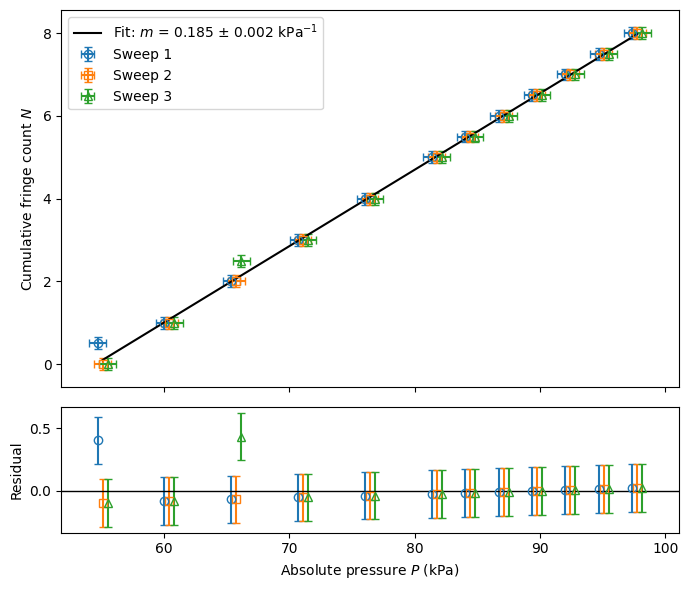

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import odr, stats

# --- Data: rows = pressure points, columns = sweeps ---
N = 8.5 - np.array(data)                     # shape (12, 3), N = 0 at lowest pressure
p_atm = 103.1
read_pressures = np.array([4, 6, 8, 10, 12, 14, 16, 20, 24, 28, 32, 36])
P = p_atm - read_pressures * 1.33322         # absolute pressure, kPa (do NOT reverse)

# --- Uncertainties ---
sigma_N = 0.5 / np.sqrt(12)                  # half-fringe rounding is assumed to be uniformly distributed
                                             # Then we divide by sqrt(12) to get the std according to https://www.mathwords.com/u/uniform_distribution.htm
sigma_P = 0.5 * 1.33322                      # gauge reading; use /np.sqrt(3) if 0.5 cm Hg is a half-division limit

# --- Fit all sweeps together ---
P_all = np.repeat(P, N.shape[1])             # each pressure appears once per sweep
N_all = N.ravel()                            # row by row, matching P_all

def line(beta, p):
    return beta[0] * p + beta[1]

fit_data = odr.RealData(P_all, N_all, sx=sigma_P, sy=sigma_N)
out = odr.ODR(fit_data, odr.Model(line), beta0=[0.2, -20]).run()
m, b = out.beta
dm, db = np.sqrt(np.diag(out.cov_beta))
print(f"m = {m:.4f} ± {dm:.4f} fringes/kPa")

# --- Per-sweep fits (repeatability) ---
for i in range(N.shape[1]):
    o = odr.ODR(odr.RealData(P, N[:, i], sx=sigma_P, sy=sigma_N),
                odr.Model(line), beta0=[m, b]).run()
    mi, dmi = o.beta[0], np.sqrt(o.cov_beta[0, 0])
    print(f"sweep {i+1}: m = {mi:.4f} ± {dmi:.4f}, b = {o.beta[1]:.2f}")

# --- Residuals and chi-squared ---
sigma_eff = np.sqrt(sigma_N**2 + (m * sigma_P)**2)
resid = N - line(out.beta, P)[:, None]       # shape (12, 3)
chi2 = np.sum((resid / sigma_eff)**2)
dof = N.size - 2
print(f"chi2/dof = {chi2:.1f}/{dof} = {chi2/dof:.2f}")

# --- Figure: data + fit, residual panel ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})
markers = ['o', 's', '^']
xx = np.linspace(P.min(), P.max(), 200)

offsets = [-0.4, 0.0, 0.4]   # kPa, horizontal shift for display only

for i in range(N.shape[1]):
    P_shift = P + offsets[i]
    ax1.errorbar(P_shift, N[:, i], xerr=sigma_P, yerr=sigma_N, fmt=markers[i],
                 mfc='none', capsize=3, label=f'Sweep {i+1}')
    ax2.errorbar(P_shift, resid[:, i], yerr=sigma_eff, fmt=markers[i],
                 mfc='none', capsize=3)

ax1.plot(xx, line(out.beta, xx), 'k-', label=f'Fit: $m$ = {m:.3f} ± {dm:.3f} kPa$^{{-1}}$')
ax1.set_ylabel('Cumulative fringe count $N$')
ax1.legend()
ax2.axhline(0, color='k', lw=1)
ax2.set_xlabel('Absolute pressure $P$ (kPa)')
ax2.set_ylabel('Residual')
plt.tight_layout()
plt.show()

beta = 1.9478e-06 ± 4.1e-08 per kPa
c_air(P_atm) = $c_{\mathrm{air}}(P_{\mathrm{atm}}) = 299 732 000 \pm 1 300$ m/s
n - 1 = 2.008e-04 ± 4.2e-06


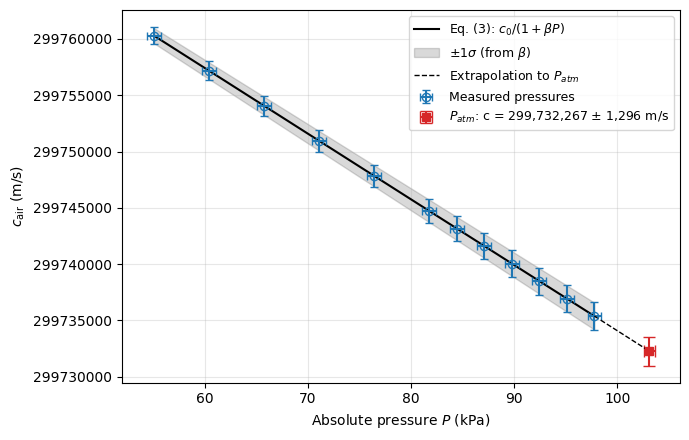

In [ ]:
# --- Applying Eq. (3): c_air = c0 / (1 + beta*P) ---
lambda_0 = 632.8e-9      # m
c0 = 299792458           # m/s, exact
L = 0.030                # m
dL = 0.0005              # m

# m, dm from the fit (fringes per kPa), so P must be in kPa
beta = m * lambda_0 / (2 * L)
dbeta = beta * np.sqrt((dm / m)**2 + (dL / L)**2)   # same as your expression
print(f"beta = {beta:.4e} ± {dbeta:.1e} per kPa")

def c_air(p, dp=sigma_P):
    denom = 1 + beta * p
    c = c0 / denom
    dc = np.sqrt((c0 * p / denom**2 * dbeta)**2 +
                 (c0 * beta / denom**2 * dp)**2)
    return c, dc

# Representative value at atmospheric pressure
dp_atm = 0.5   # kPa: your estimate of how well the airport value represents the lab
c_atm, dc_atm = c_air(p_atm, dp_atm)
print(f"c_air(P_atm) = $c_{{\\mathrm{{air}}}}(P_{{\\mathrm{{atm}}}}) = 299 732 000 \\pm 1 300$ m/s")
print(f"n - 1 = {beta * p_atm:.3e} ± {dbeta * p_atm:.1e}")

# --- Plot ---
c_pts, dc_pts = c_air(P)                 # at your measured pressures
pp = np.linspace(P.min(), P.max(), 300)   # was np.linspace(0, 105, 300)
c_line, dc_line = c_air(pp, 0)           # band shows the beta uncertainty only

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(pp, c_line, 'k-', label=r'Eq. (3): $c_0/(1+\beta P)$')
ax.fill_between(pp, c_line - dc_line, c_line + dc_line, color='k', alpha=0.15,
                label=r'$\pm1\sigma$ (from $\beta$)')
ax.errorbar(P, c_pts, yerr=dc_pts, xerr=sigma_P, fmt='o', mfc='none', capsize=3,
            label='Measured pressures')
ax.errorbar(p_atm, c_atm, yerr=dc_atm, xerr=dp_atm, fmt='s', color='C3', capsize=4,
            label=f'$P_{{atm}}$: $c_{{\\mathrm{{air}}}}(P_{{\\mathrm{{atm}}}}) = 299 732 000 \\pm 1 300$ m/s')
ax.ticklabel_format(axis='y', style='plain', useOffset=False)
ax.set_xlabel('Absolute pressure $P$ (kPa)')
ax.set_ylabel(r'$c_{\mathrm{air}}$ (m/s)')

pe = np.linspace(P.max(), p_atm, 50)
c_ext, _ = c_air(pe, 0)
ax.plot(pe, c_ext, 'k--', lw=1, label='Extrapolation to $P_{atm}$')


ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()